# Good-vertex variables: signal versus background
Run on LPC in your Coffea notebook environment. This is a separate notebook; the original GoodVertexDef.ipynb is unchanged.

The signal file and point follow the original notebook: Trial_optimize.coffea, m1=100, delta=0.2, ctau=100. The background path is assumed to be beside it: Bkg_optimize.coffea. Check these paths in the settings cell.

Plots compare shapes: each distribution is divided by its own sum of displayed histogram bins. The y-axis is fraction of histogram total per bin, not efficiency, probability density, or luminosity-normalized yield. All background samples actually present in a histogram are combined using their stored contents; no new cross-section weighting is applied. Counts can be vertex entries or weighted sums, depending on the producer—not event counts automatically. Underflow/overflow are excluded and reported separately for numeric axes.

Matching variable names, cut names, and binning does not establish identical physics selections. Confirm both producers use the intended lptvtx collection and comparable cuts. The local bkg_histo.py inspected during preparation still had a signal-only filling condition; if the background output is empty, correct its producer on LPC and regenerate with consent. Missing quantities are reported and skipped. A plot cannot recover quantities absent from the Coffea output.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from coffea import util

LPC_REPO = Path('/uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe')
sys.path.insert(0, str(LPC_REPO / 'python_analysis/analysisTools'))
import utils


In [2]:
# Change settings here, then rerun the cells below.
f_sig = LPC_REPO / 'python_analysis/coffea/VertexRes2026/Trial_optimize.coffea'
f_bkg = LPC_REPO / 'python_analysis/coffea/VertexRes2026/Bkg_optimize.coffea'
selected_cut = 'cut0'
m1, delta, ctau = 100, 0.2, 100

# None includes ALL background samples stored in each histogram.
# To restrict, provide exact histogram sample names, e.g. ['bkg_2024_DY_EE'].
background_samples = None

# Original notebook variables, followed by additional lptvtx quantities.
variables = ['chi2', 'mass',  
             'vxy', 'pt', 'dr', 'eta', 'phi']
log_y = True
# Default shows all regular bins, with no additional x-range cut.
x_limits = {}  # Example: {'mass': (0, 1)}; normalization still uses all regular bins.
labels = {
    'ossf': 'Vertex charge sign',
    'chi2': r'Vertex reduced $\chi^2$',
    'mass': 'Refitted vertex mass [GeV]',
    'eleDphi': r'Electron $|\Delta\phi|$ [rad]',
    'mindxy': r'Minimum electron $|d_{xy}|$ [cm]',
    'dxy': r'Electron $d_{xy}$ [cm] (check producer definition)',
    'IDcut': 'Both electrons pass ID',
    'maxMiniIso': 'Maximum corrected relative mini-isolation',
    'vxy': r'Vertex $v_{xy}$ [cm]',
    'pt': r'Vertex $p_T$ [GeV]',
    'dr': r'Vertex electron-pair $\Delta R$',
    'eta': r'Vertex $\eta$',
    'phi': r'Vertex $\phi$ [rad]',
}


In [3]:
# Same output structure as the original notebook: histograms are element 0.
sig_histo = util.load(str(f_sig))[0]
bkg_histo = util.load(str(f_bkg))[0]

signal_info = utils.get_signal_point_dict(sig_histo)
match = signal_info[(signal_info.m1 == m1) & (signal_info.delta == delta) & (signal_info.ctau == ctau)]
if len(match) != 1:
    raise ValueError(f'Expected exactly one signal sample, found {len(match)} for {(m1, delta, ctau)}.')
signal_sample = match['name'].iloc[0]
print('Signal file:', f_sig)
print('Background file:', f_bkg)
print('Signal sample:', signal_sample)
print('Cut:', selected_cut)
print('Shape normalization: each regular-bin histogram sum is set to one.')

available_variables = []
for variable in variables:
    missing = [name for name, output in [('signal', sig_histo), ('background', bkg_histo)] if variable not in output]
    if missing:
        print(f'SKIP {variable}: missing from {", ".join(missing)} output.')
    else:
        available_variables.append(variable)
if not available_variables:
    raise ValueError('No requested histograms are present in both outputs.')


Signal file: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/Trial_optimize.coffea
Background file: /uscms/home/reshmar/nobackup/IDMe_Run3_Collab/CMSSW_13_0_13/src/iDMe/python_analysis/coffea/VertexRes2026/Bkg_optimize.coffea
Signal sample: sig_2022_Mchi-110p0_dMchi-20p0_ctau-100
Cut: cut0
Shape normalization: each regular-bin histogram sum is set to one.
SKIP vxy: missing from signal output.
SKIP pt: missing from signal output.
SKIP dr: missing from signal output.
SKIP eta: missing from signal output.
SKIP phi: missing from signal output.


In [4]:
def selected_histogram(output, variable, sample):
    histogram = output[variable]
    if selected_cut not in list(histogram.axes['cut']):
        raise ValueError(f'{variable}: cut {selected_cut} is missing.')
    if sample not in list(histogram.axes['samp']):
        raise ValueError(f'{variable}: sample {sample} is missing.')
    result = histogram[{'samp': sample, 'cut': selected_cut}]
    if len(result.axes) != 1:
        raise ValueError(f'{variable}: expected one physical axis after sample/cut selection.')
    return result


def same_binning(first, second):
    a, b = first.axes[0], second.axes[0]
    if a.traits.discrete != b.traits.discrete:
        return False
    if a.traits.discrete:
        return list(a) == list(b)
    return a.edges.shape == b.edges.shape and np.allclose(a.edges, b.edges, rtol=0, atol=1e-12)


def prepare_comparison(variable):
    signal = selected_histogram(sig_histo, variable, signal_sample)
    available = list(bkg_histo[variable].axes['samp'])
    names = available if background_samples is None else list(background_samples)
    if not names or len(names) != len(set(names)):
        raise ValueError(f'{variable}: choose a nonempty, unique background sample list.')
    background = None
    print(f'\n{variable}: background samples included ({len(names)}):')
    for name in names:
        part = selected_histogram(bkg_histo, variable, name)
        if not same_binning(signal, part):
            raise ValueError(f'{variable}: signal/background binning differs for {name}; regenerate with common binning or explicitly rebin.')
        print(f'  {name}: regular-bin total = {np.asarray(part.values()).sum():g}')
        background = part.copy() if background is None else background + part
    values_sig = np.asarray(signal.values(), dtype=float)
    values_bkg = np.asarray(background.values(), dtype=float)
    if not np.all(np.isfinite(values_sig)) or not np.all(np.isfinite(values_bkg)):
        raise ValueError(f'{variable}: non-finite histogram contents.')
    # This notebook uses nonnegative, unit-total shape comparisons.
    if np.any(values_sig < 0) or np.any(values_bkg < 0):
        raise ValueError(f'{variable}: negative bin contents; inspect event weights before choosing a signed-weight plotting convention.')
    return signal, background, values_sig, values_bkg



chi2: background samples included (1):
  bkg_2024_DY_EE: regular-bin total = 26
Signal regular-bin total: 16291
Background regular-bin total: 26
Normalized sums: signal=1.000000, background=1.000000


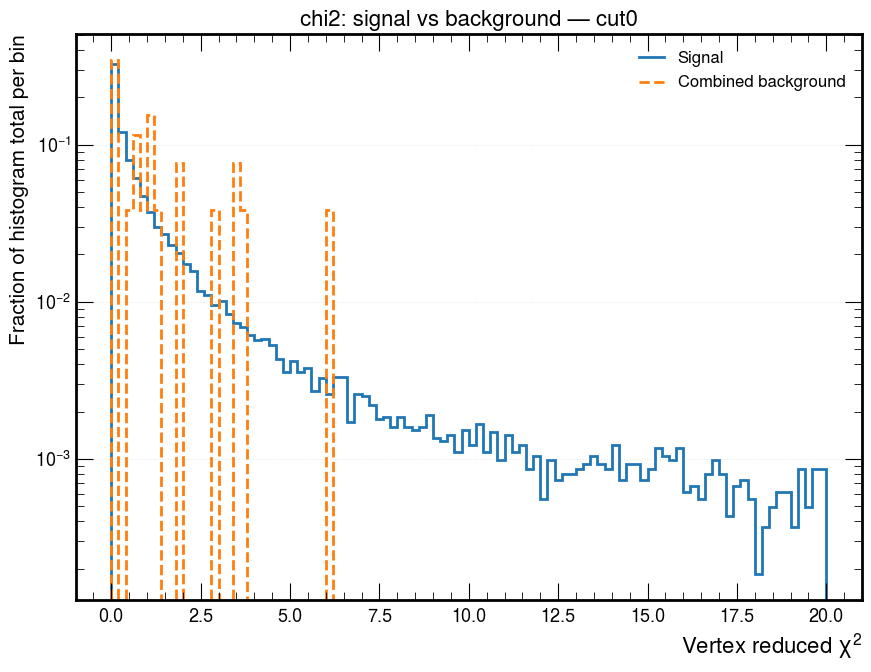


mass: background samples included (1):
  bkg_2024_DY_EE: regular-bin total = 1
Signal regular-bin total: 1638
Background regular-bin total: 1
Normalized sums: signal=1.000000, background=1.000000


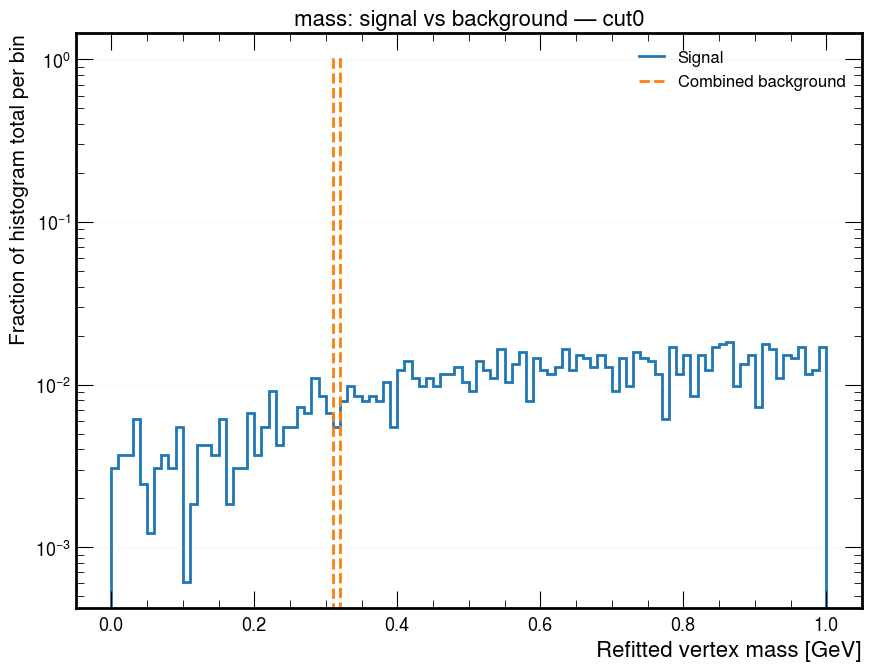


Histogram totals (not automatically event counts):
variable  signal regular-bin total  background regular-bin total  signal total including flow  background total including flow
    chi2                   16291.0                          26.0                      27665.0                             36.0
    mass                    1638.0                           1.0                      27665.0                             36.0
Numeric-axis flow totals include underflow/overflow; plots exclude them.


In [5]:
comparison_summary = []
for variable in available_variables:
    signal, background, counts_sig, counts_bkg = prepare_comparison(variable)
    total_sig, total_bkg = counts_sig.sum(), counts_bkg.sum()
    comparison_summary.append({
        'variable': variable, 'signal regular-bin total': total_sig,
        'background regular-bin total': total_bkg,
        'signal total including flow': np.asarray(signal.values(flow=True)).sum(),
        'background total including flow': np.asarray(background.values(flow=True)).sum(),
    })
    print(f'Signal regular-bin total: {total_sig:g}')
    print(f'Background regular-bin total: {total_bkg:g}')
    if total_sig <= 0 or total_bkg <= 0:
        print('SKIP plot: one distribution is empty. Check producer selection and filling.')
        continue
    shape_sig, shape_bkg = counts_sig / total_sig, counts_bkg / total_bkg
    print(f'Normalized sums: signal={shape_sig.sum():.6f}, background={shape_bkg.sum():.6f}')
    axis = signal.axes[0]
    fig, ax = plt.subplots(figsize=(9, 7))
    if axis.traits.discrete:
        positions = np.arange(len(counts_sig))
        ax.plot(positions, np.where(shape_sig > 0, shape_sig, np.nan) if log_y else shape_sig,
                'o-', color='tab:blue', label='Signal')
        ax.plot(positions, np.where(shape_bkg > 0, shape_bkg, np.nan) if log_y else shape_bkg,
                's--', color='tab:orange', label='Combined background')
        ax.set_xticks(positions)
        ax.set_xticklabels([str(value) for value in axis])
    else:
        ax.stairs(shape_sig, axis.edges, color='tab:blue', linewidth=2, label='Signal')
        ax.stairs(shape_bkg, axis.edges, color='tab:orange', linewidth=2,
                  linestyle='--', label='Combined background')
    if log_y:
        ax.set_yscale('log')
    else:
        ax.set_ylim(bottom=0)
    if variable in x_limits:
        ax.set_xlim(*x_limits[variable])
    ax.set_xlabel(labels.get(variable, variable), fontsize=16)
    ax.set_ylabel('Fraction of histogram total per bin', fontsize=15)
    ax.set_title(f'{variable}: signal vs background — {selected_cut}', fontsize=16)
    ax.tick_params(axis='both', labelsize=13)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=12)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

comparison_summary = pd.DataFrame(comparison_summary)
print('\nHistogram totals (not automatically event counts):')
print(comparison_summary.to_string(index=False))
print('Numeric-axis flow totals include underflow/overflow; plots exclude them.')
